
****I-LSR
Num conflicts: 7483
Total rank disagreement: 226388.0
Rank disagreements' mean: 30.25364158759856
Rank disagreements' std: 30.763869836658053

****LSR
Num conflicts: 8923
Total rank disagreement: 308000.0
Rank disagreements' mean: 34.51753894430124
Rank disagreements' std: 33.037164224713216

****Rank Centrality
Num conflicts: 17240
Total rank disagreement: 1191102.0
Rank disagreements' mean: 69.08944315545244
Rank disagreements' std: 61.739046521234656

****Survey
Num conflicts: 49040
Total rank disagreement: 7247651.0
Rank disagreements' mean: 147.79059951060358
Rank disagreements' std: 120.5373615079491


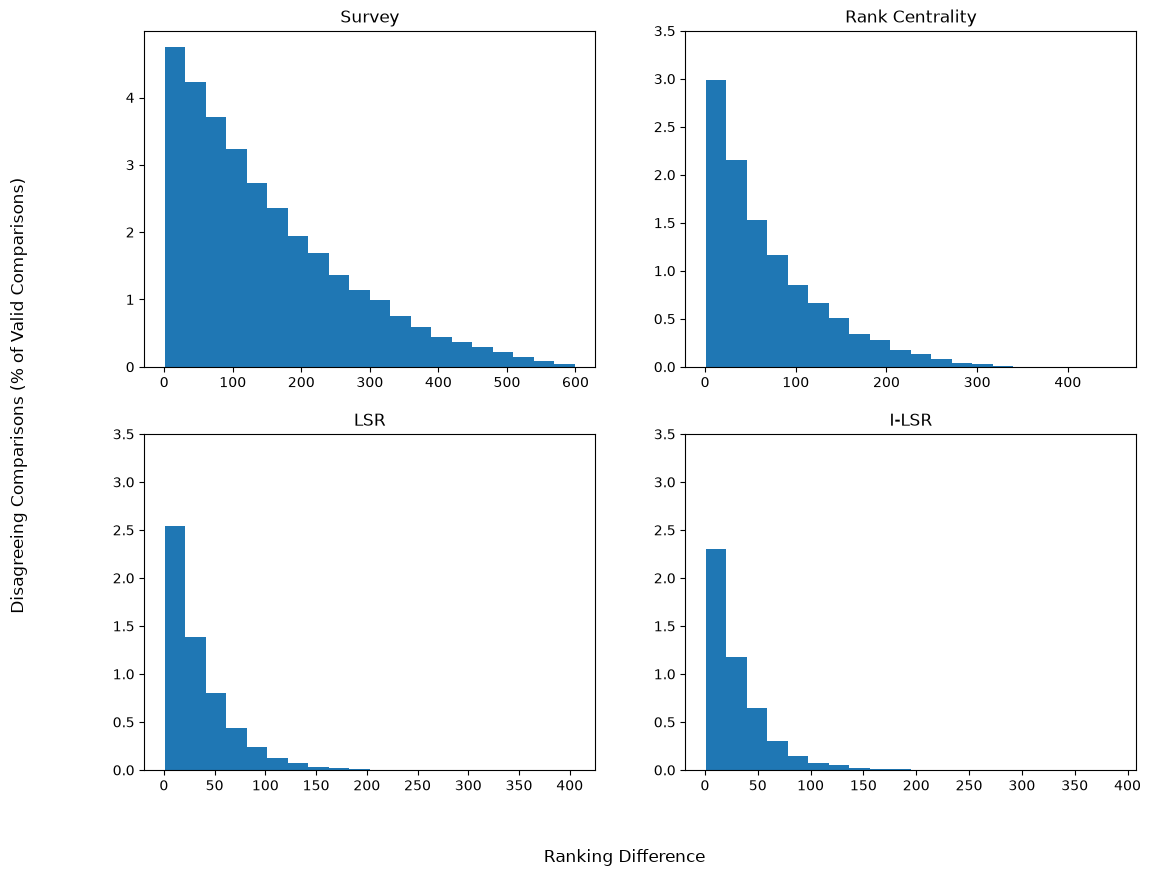

Getting quantile prediction performances:

CNN3x3************************
	Rank Correlation:
		spearmanr: 0.78
			95% Confidence Interval: [0.75 0.82]	Standard Error: 0.02
	Quantile prediction:

		matthews_corrcoef: 0.38
			95% Confidence Interval: [0.33 0.43]	Standard Error: 0.03
		Dichotomy 1:
		matthews_corrcoef: 0.39
			95% Confidence Interval: [0.30 0.48]	Standard Error: 0.05
		Dichotomy 2:
		matthews_corrcoef: 0.53
			95% Confidence Interval: [0.46 0.59]	Standard Error: 0.04
		Dichotomy 3:
		matthews_corrcoef: 0.73
			95% Confidence Interval: [0.67 0.78]	Standard Error: 0.03
		Dichotomy 4:
		matthews_corrcoef: 0.74
			95% Confidence Interval: [0.67 0.81]	Standard Error: 0.03

Random Forest Regressor**********************
	Rank Correlation:
		spearmanr: 0.59
			95% Confidence Interval: [0.53 0.64]	Standard Error: 0.03
	Quantile prediction:

		matthews_corrcoef: 0.20
			95% Confidence Interval: [0.16 0.25]	Standard Error: 0.02
		Dichotomy 1:
		matthews_corrcoef: 0.08
			95% Confide

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from utils import get_ranking_and_quantile_metrics, show_scatter_samples, SmartRanker, get_metrics_diff_confidence_intervals

pd.set_option("display.precision",2)

def quantile_analysis(df, wi_column):

    print("Getting quantile prediction performances:")

    print("\nCNN3x3************************")
    get_ranking_and_quantile_metrics(df[wi_column].values, df["CNN_3x3_hv271_reg"].values)
    print("\nRandom Forest Regressor**********************")
    get_ranking_and_quantile_metrics(df[wi_column].values, df["rf_regressor_hv271"].values)
    print("\nChatGPT*************************")
    get_ranking_and_quantile_metrics(df[wi_column].values, df["ranking"].values)
    print("\nV191*************************")
    get_ranking_and_quantile_metrics(df[wi_column].values, df["wealth_index_v191"].values)
    print("\nRandom*************************")
    get_ranking_and_quantile_metrics(df[wi_column].values, "random")

    print("Now checking if there is a significant difference between different models")

    print("\nCNN3x3 - Random Forest Regressor ************************")
    get_metrics_diff_confidence_intervals(df[wi_column].values,df["CNN_3x3_hv271_reg"].values,df["rf_regressor_hv271"].values)
    print("\nCNN3x3 - ChatGPT ************************")
    get_metrics_diff_confidence_intervals(df[wi_column].values,df["CNN_3x3_hv271_reg"].values,df["ranking"].values)
    print("\nRandom Forest Regressor - ChatGPT ************************")
    get_metrics_diff_confidence_intervals(df[wi_column].values,df["rf_regressor_hv271"].values,df["ranking"].values)

    show_scatter_samples(df,wi_column,"CNN_3x3_hv271_reg")

    plt.show()
def main():

    wi_column = "wealth_index_hv271" # The name of the wealth index column

    df = pd.read_csv("data/data.csv",index_col=False)

    comp_df = pd.read_csv("data/comparisons.csv")

    sr = SmartRanker(comp_df,df,wi_column)
    df = sr.rank()

    df.rename(columns={"ilsr_pairwise":"ranking"},inplace=True)

    quantile_analysis(df, wi_column)

    sr.show_num_3_cycles()

main()
